# 02 · Corrected Approach (no data leakage)

The fix is simple: **split the real data first**, and only use the training part to make synthetic data. The test set stays 100% real teenagers that the model and CTGAN have never seen.

1. Split the real data into train (75%) and test (25%)
2. Train CTGAN only on the depression cases in the **training** set
3. Add synthetic cases to the **training** set only
4. Test both models on the same **real** test set

In [1]:
import random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, recall_score, precision_score,
                             f1_score, confusion_matrix, classification_report)
from sdv.single_table import CTGANSynthesizer
from sdv.metadata import Metadata

warnings.filterwarnings("ignore")

# Fix the random seeds so the results are repeatable
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

df = pd.read_csv("../data/Teen_Mental_Health_Dataset.csv")
categorical_cols = ['gender', 'platform_usage', 'social_interaction_level']
print(df.shape)

(1200, 13)


In [2]:
def encode(data, encoders):
    """Turn text columns into numbers with the same encoders every time."""
    data = data.copy()
    for col in categorical_cols:
        known = set(encoders[col].classes_)
        data[col] = data[col].astype(str).apply(lambda x: x if x in known else encoders[col].classes_[0])
        data[col] = encoders[col].transform(data[col])
    return data.drop(columns=['depression_label']), data['depression_label']

encoders = {col: LabelEncoder().fit(df[col].astype(str)) for col in categorical_cols}

# Step 1: split the REAL data first
train_df, test_df = train_test_split(df, test_size=0.25, random_state=SEED, stratify=df['depression_label'])
print(f"Real depression cases in training set: {train_df['depression_label'].sum()}")
print(f"Real depression cases in test set:     {test_df['depression_label'].sum()} out of {len(test_df)}")

X_test, y_test = encode(test_df, encoders)

Real depression cases in training set: 23
Real depression cases in test set:     8 out of 300


## Baseline (real training data only)

In [3]:
X_train, y_train = encode(train_df, encoders)
baseline = LogisticRegression(max_iter=1000, random_state=SEED).fit(X_train, y_train)
y_pred_base = baseline.predict(X_test)
print(classification_report(y_test, y_pred_base, target_names=['No depression', 'Depression'], zero_division=0))

               precision    recall  f1-score   support

No depression       0.98      1.00      0.99       292
   Depression       1.00      0.38      0.55         8

     accuracy                           0.98       300
    macro avg       0.99      0.69      0.77       300
 weighted avg       0.98      0.98      0.98       300



## CTGAN trained on the training set only

In [4]:
minority_train = train_df[train_df['depression_label'] == 1].reset_index(drop=True)
print(f"CTGAN learns from {len(minority_train)} real depression cases")

metadata = Metadata.detect_from_dataframe(minority_train)
synthesizer = CTGANSynthesizer(metadata, epochs=300)
synthesizer.fit(minority_train)

n_needed = (train_df['depression_label'] == 0).sum() - len(minority_train)   # balance the training set
synthetic = synthesizer.sample(num_rows=n_needed)
synthetic['depression_label'] = 1

train_aug = pd.concat([train_df, synthetic], ignore_index=True)
print(train_aug['depression_label'].value_counts())

CTGAN learns from 23 real depression cases


depression_label
0    877
1    877
Name: count, dtype: int64


In [5]:
X_train_aug, y_train_aug = encode(train_aug, encoders)
model_ctgan = LogisticRegression(max_iter=1000, random_state=SEED).fit(X_train_aug, y_train_aug)
y_pred_ctgan = model_ctgan.predict(X_test)
print(classification_report(y_test, y_pred_ctgan, target_names=['No depression', 'Depression'], zero_division=0))

               precision    recall  f1-score   support

No depression       0.99      0.99      0.99       292
   Depression       0.71      0.62      0.67         8

     accuracy                           0.98       300
    macro avg       0.85      0.81      0.83       300
 weighted avg       0.98      0.98      0.98       300



## Before vs after, on the same real test set

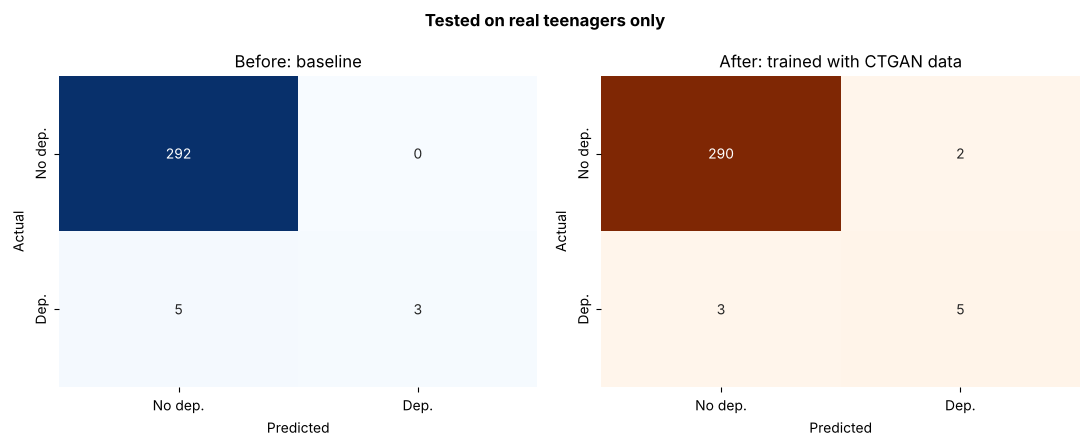

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
fig.suptitle('Tested on real teenagers only', fontweight='bold')
labels = ['No dep.', 'Dep.']
sns.heatmap(confusion_matrix(y_test, y_pred_base), annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=labels, yticklabels=labels, cbar=False)
axes[0].set_title('Before: baseline'); axes[0].set_ylabel('Actual'); axes[0].set_xlabel('Predicted')
sns.heatmap(confusion_matrix(y_test, y_pred_ctgan), annot=True, fmt='d', cmap='Oranges', ax=axes[1],
            xticklabels=labels, yticklabels=labels, cbar=False)
axes[1].set_title('After: trained with CTGAN data'); axes[1].set_ylabel('Actual'); axes[1].set_xlabel('Predicted')
plt.tight_layout()
plt.savefig('../images/before_after_confusion.png', dpi=150)
plt.show()

In [7]:
summary = pd.DataFrame({
    'Metric': ['Accuracy', 'Recall (depression)', 'Precision (depression)', 'F1 (depression)'],
    'Baseline': [accuracy_score(y_test, y_pred_base), recall_score(y_test, y_pred_base),
                 precision_score(y_test, y_pred_base, zero_division=0), f1_score(y_test, y_pred_base)],
    'With CTGAN': [accuracy_score(y_test, y_pred_ctgan), recall_score(y_test, y_pred_ctgan),
                   precision_score(y_test, y_pred_ctgan, zero_division=0), f1_score(y_test, y_pred_ctgan)],
}).round(3)
summary

,Metric,Baseline,With CTGAN
0,Accuracy,0.983,0.983
1,Recall (depression),0.375,0.625
2,Precision (depression),1.000,0.714
3,F1 (depression),0.545,0.667


## What this shows

- CTGAN **does help**: the model finds more of the real depression cases.
- But it also raises more **false alarms**, so precision goes down.
- The real test set has only a few depression cases, so these numbers can change a lot with a different split or random seed. A bigger real dataset, or cross-validation, would give a more reliable answer.